# Phase 4h: the Fang et al. (2025) test

**Status:** done 2026-11-04. Driver: `code/R/04h_fang_test.R`. Results: `results/2026-11-04/fang/`.

**What Fang did:** Fang, Lee & Li (2025) regress renewable energy consumption on AI job postings, policy uncertainty and controls, all in logs, with state fixed effects, for 50 states + DC in 2018-2021 (N = 204). Their AI coefficient runs from 0.0396 to 0.0561.

**How this differs from the Zhang test (4b-4e):** different outcome (all renewable energy use, not the electricity share), different AI measure (job postings, not data-center jobs), different controls, no year effects and no lag. The Zhang test stays as it is.

In [1]:
import pandas as pd
from IPython.display import display, Image
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 70); pd.set_option('display.max_rows', 100)
L = '../logs/2026-11-04/'
post = pd.read_csv('../data/ai_job_postings_state.csv')
print('Postings:', post.shape, '| Fang panel:', pd.read_csv('../data/fang_panel.csv').shape)

Postings: (408, 13) | Fang panel: (561, 41)


## Coverage

Number of areas with data, out of 51, by variable and year.

In [2]:
display(pd.read_csv(L + 'fang_coverage.csv'))

,variable,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,first,last
0,re_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
1,wind_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
2,solar_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
3,geothermal_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
4,hydro_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
5,biomass_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
6,total_energy_bbtu,51,51,51,51,51,51,51,51,51,51,0,2015,2024
7,ep_tetcd,51,51,51,51,51,51,51,51,51,51,0,2015,2024
8,edu_bach_per1000,51,51,51,51,51,51,51,51,51,51,0,2015,2024
9,gdp_real_musd2017,51,51,51,51,51,51,51,51,51,51,51,2015,2025


## AI job postings: where each year comes from

In [3]:
t = post.groupby(['year', 'edition', 'vendor', 'vintage', 'figure'], dropna=False).agg(sum_of_51=('postings', 'sum'), page=('page', 'first')).reset_index()
t['national_change_pct'] = t.sum_of_51.pct_change().mul(100).round(0)
display(t)

,year,edition,vendor,vintage,figure,sum_of_51,page,national_change_pct
0,2018,2019,Burning Glass,ed2019_bg,Fig. 4.1.8 shows a scatter; values from its linked sheet,189030.0,82.0,NaN
1,2019,2022,Emsi Burning Glass,ed2022_ebg,"Public-data sheet, tab AI Job Postings by State; not printed in th...",325702.0,NaN,72.0
2,2020,2022,Emsi Burning Glass,ed2022_ebg,"Public-data sheet, tab AI Job Postings by State; not printed in th...",296937.0,NaN,-9.0
3,2021,2022,Emsi Burning Glass,ed2022_ebg,Fig. 4.1.6,404074.0,9.0,36.0
4,2022,2023,Lightcast,ed2023_lc,Fig. 4.1.6; share Fig. 4.1.8 (p. 11),795624.0,10.0,97.0
5,2023,2024,Lightcast,ed2024_lc,Fig. 4.2.7; share Fig. 4.2.9 (p. 18),461225.0,17.0,-42.0
6,2024,2025,Lightcast,ed2025_lc,Fig. 4.2.8; share Fig. 4.2.10 (p. 17),658548.0,16.0,43.0
7,2025,2026,Lightcast,ed2026_lc,Fig. 4.4.10; share Fig. 4.4.11 (p. 40),994372.0,40.0,51.0


## How to read the postings series

**In the postings extension (2019-2024), almost every year comes from a different edition. So a state's year-to-year change mixes real change with method changes.** Year effects remove shifts that hit all states proportionally. The share-of-national row can't test this: once year effects are in, it equals the postings row by construction (-0.0475 vs -0.0479). Anything uneven stays in as noise, and the edition overlap and share-change tables are the evidence on that. Data-center jobs (BLS, one consistent series) remain the more reliable extension measure.

National totals swing +97% in 2022 and -42% in 2023 around reported method changes. Those are the shifts year effects can absorb, but only if they hit states proportionally.

## Checks on the postings table

In [4]:
display(pd.read_csv(L + 'ai_postings_checks.csv'))

,year,check,result,detail
0,2018,51 rows,ok,"sum of 51 = 189,030; yoy"
1,2019,51 rows,ok,"sum of 51 = 325,702; yoy +72%"
2,2020,51 rows,ok,"sum of 51 = 296,937; yoy -9%"
3,2021,51 rows,ok,"sum of 51 = 404,074; yoy +36%"
4,2022,51 rows,ok,"sum of 51 = 795,624; yoy +97%"
5,2023,51 rows,ok,"sum of 51 = 461,225; yoy -42%"
6,2024,51 rows,ok,"sum of 51 = 658,548; yoy +43%"
7,2025,51 rows,ok,"sum of 51 = 994,372; yoy +51%"
8,2022,sum vs national total implied by published shares,ok,"implied 795,471; sum 795,624; gap -0.02%; max |published - derived..."
9,2023,sum vs national total implied by published shares,ok,"implied 461,332; sum 461,225; gap +0.02%; max |published - derived..."


## Edition overlap

Levels can't be compared when one edition covers Jan-Sep and the other the full year, but each state's **share of U.S. AI postings** can. These are the only years two editions report for all states.

**Reading it:** the state pattern is very similar across editions, but high correlations are driven by the ordering of large and small states, so they don't clear within-state noise. For 2019 the median state's share still differs by 14.8% (SD of the log ratio 0.162), part of which is Jan-Sep against the full year. For 2020, with both full years, the median gap is 0.7%, so a one-year revision within Burning Glass is small.

In [5]:
display(pd.read_csv(L + 'ai_postings_overlap.csv').drop(columns=['comparison']))

,year,edition_a,edition_b,n_states,pearson_share,spearman_share,pearson_ln_share,level_ratio_b_over_a,sd_ln_share_ratio,median_abs_pct_gap,largest_gaps
0,2019,"2019 edition, Jan-Sep","2022 edition, full year",51,0.9978,0.9954,0.9969,2.0000,0.1616,14.7934,MT -45%; AK -45%; MS -41%
1,2020,2021 edition,2022 edition,51,1.0000,0.9996,1.0000,0.9883,0.0116,0.6547,WV +4%; OR +3%; VT +3%
2,2021,"2022 edition, PDF map","2022 edition, sheet",51,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,AK +0%; PA +0%; ND +0%


### Four states, across editions

The 2023-2026 editions print a share history for CA, NY, TX and WA, and it's the same in all four. For 2022 onward it matches our table. For 2018-2021 it's Lightcast's restated history, which differs from the Burning Glass tables we use. **WA's fall from 4.8% to 3.9% at 2021-2022 in our table doesn't exist in Lightcast's own series (3.94 to 3.93): it's a method change.**

In [6]:
display(pd.read_csv(L + 'ai_postings_select_states.csv'))

,state,year,series_2023,series_2024,series_2025,series_2026,table_share_pct,table_edition,alt_share_pct
0,CA,2018,22.522,22.52,22.52,22.522,25.959,2019,NaN
1,CA,2019,24.619,24.62,24.62,24.619,24.512,2022,27.458
2,CA,2020,20.877,20.88,20.88,20.877,21.055,2022,21.113
3,CA,2021,19.507,19.51,19.51,19.507,19.857,2022,NaN
4,CA,2022,17.867,17.87,17.87,17.867,17.870,2023,NaN
5,CA,2023,NaN,15.31,15.31,15.314,15.310,2024,NaN
6,CA,2024,NaN,NaN,15.70,15.697,15.700,2025,NaN
7,CA,2025,NaN,NaN,NaN,17.185,17.180,2026,NaN
8,NY,2018,7.037,7.04,7.04,7.037,8.221,2019,NaN
9,NY,2019,7.686,7.69,7.69,7.686,7.573,2022,8.811


### How much state shares move each year

SD across states of the year-to-year change in ln(state share). Postings shares move 1.3 to 3.2 times as much as data-center jobs in every step, including the two same-edition steps. Steps across editions are somewhat larger on average (0.227 against 0.195). So postings are noisy at the state level for more reasons than edition changes.

In [7]:
display(pd.read_csv(L + 'ai_postings_share_changes.csv'))

,step,editions,same_edition,national_change_pct,sd_ln_share_change_postings,median_abs_ln_share_change,sd_ln_share_change_dc_jobs,n_dc_jobs,largest
0,2018->2019,2019->2022,False,72.3018,0.2230,0.1395,0.1196,51,MS +90%; IN +81%; AK +81%
1,2019->2020,2022->2022,True,-8.8317,0.1738,0.1155,0.1294,51,HI +111%; ID +63%; ND +33%
2,2020->2021,2022->2022,True,36.0807,0.2166,0.1761,0.0957,51,AR +95%; WY +82%; ID +70%
3,2021->2022,2022->2023,False,96.9006,0.2663,0.1313,0.1045,51,AR +139%; OK +99%; KS +90%
4,2022->2023,2023->2024,False,-42.0298,0.2493,0.1400,0.0829,51,AK +133%; MT +85%; ND +82%
5,2023->2024,2024->2025,False,42.7824,0.2004,0.1217,0.0618,51,MT +93%; WV +70%; MD -36%
6,2024->2025,2025->2026,False,50.9946,0.1951,0.0905,0.0775,47,VT +126%; WY +78%; WV +69%


# Part B: models

All results are associations. **Data-center jobs (BLS, one consistent series) are the more reliable extension measure.** Postings are Fang's measure, and they're stitched from different report editions.

In [8]:
T = '../results/2026-11-04/fang/tables/'
print('Gate:', pd.read_csv('../results/2026-11-04/fang/gate.csv').ok.all())

Gate: True


## 1. Replication: what Fang did, and what we get

**What we did:** Fang's equation 2 on 2018-2021 with DC, state fixed effects only, adding controls one at a time (their Table 2).

**What we find: it doesn't reproduce on current data.** Column 6 is -0.0188 (p = 0.317) against Fang's +0.0531.

**Why, as far as we can tell:** in October 2023, EIA changed how SEDS counts wind, solar, hydro and geothermal, for all years. Before, it counted them at about the fuel a fossil plant would have burned. Now it counts the electricity's own energy content. Fang's data end in 2021, so they use the old way. Biomass doesn't change, so "total renewables" today is mostly biomass (59-68% of the U.S. total in 2018-2024).

**The check:** we rebuilt the total on approximately the old basis: biomass + k x the other four, with k = 2.3, 2.6 and 2.9. It's approximate, because one k stands in for each year's heat rate. **The positive sign comes back:** column 2 is +0.0342 (p = 0.025) at k = 2.6, against Fang's +0.0452. Column 6 is +0.0216 (p = 0.287), positive but about 40% of Fang's and not significant.

**Vintage of postings isn't the cause:** using each year as first published gives -0.0414 (p = 0.014) in column 6.

In [9]:
display(pd.read_csv(T + 'replication.csv'))

,Version,"Measure, sample",N,(1) AI,(2) + EPU,(3) + EP,(4) + GDP,(5) + POP,(6) + EDU
0,Fang Table 2 (published),"AI postings, 2018-2021",204,0.0428*** (0.015),0.0452*** (0.015),0.0396** (0.015),0.0548*** (0.016),0.0561*** (0.019),0.0531*** (0.019)
1,Current SEDS,"AI postings, 2018-2021",204,-0.0288** (0.0141),-0.0100 (0.0139),-0.0189 (0.0159),-0.0159 (0.0183),-0.0183 (0.0186),-0.0188 (0.0187)
2,"Current SEDS, same vintage","AI postings, 2019-2021",153,0.0023 (0.0266),-0.0240 (0.0246),-0.0762* (0.0400),-0.0680* (0.0401),-0.0851* (0.0435),-0.0852* (0.0437)
3,"Current SEDS, as first published","AI postings, 2018-2021",204,-0.0355*** (0.0107),-0.0152 (0.0116),-0.0357** (0.0152),-0.0345** (0.0158),-0.0412** (0.0166),-0.0414** (0.0166)
4,"Approx. old SEDS, k = 2.3","AI postings, 2018-2021",204,0.0180 (0.0144),0.0284* (0.0149),0.0166 (0.0169),0.0188 (0.0195),0.0162 (0.0198),0.0165 (0.0199)
5,"Approx. old SEDS, k = 2.6","AI postings, 2018-2021",204,0.0251* (0.0145),0.0342** (0.0151),0.0219 (0.0171),0.0237 (0.0198),0.0213 (0.0201),0.0216 (0.0202)
6,"Approx. old SEDS, k = 2.9","AI postings, 2018-2021",204,0.0313** (0.0147),0.0393** (0.0153),0.0265 (0.0174),0.0281 (0.0201),0.0257 (0.0204),0.0262 (0.0205)
7,Current SEDS,"Data-center jobs, 2018-2021",204,-0.0950* (0.0508),-0.0503 (0.0487),-0.0735 (0.0526),-0.0674 (0.0536),-0.0651 (0.0541),-0.0655 (0.0542)
8,"Approx. old SEDS, k = 2.6","Data-center jobs, 2018-2021",204,0.0144 (0.0528),0.0299 (0.0537),-0.0216 (0.0572),-0.0272 (0.0583),-0.0220 (0.0587),-0.0218 (0.0589)


## 2. Bridge: which step changes the answer

Each row makes one change. Current SEDS.

- **Adding year effects** matters most for postings: -0.0188 becomes -0.1095 (p = 0.004). Fang's spec has no year effects, so it attributes national trends in renewables and postings to AI.
- **With the lag, clustering and longer sample,** neither measure is significant: postings -0.0479 (p = 0.109), data-center jobs -0.0567 (p = 0.208).
- **The share row equals the postings row** once year effects are in. That's algebra, not a test: ln(share) differs from ln(postings) only by the national total, which year effects absorb.

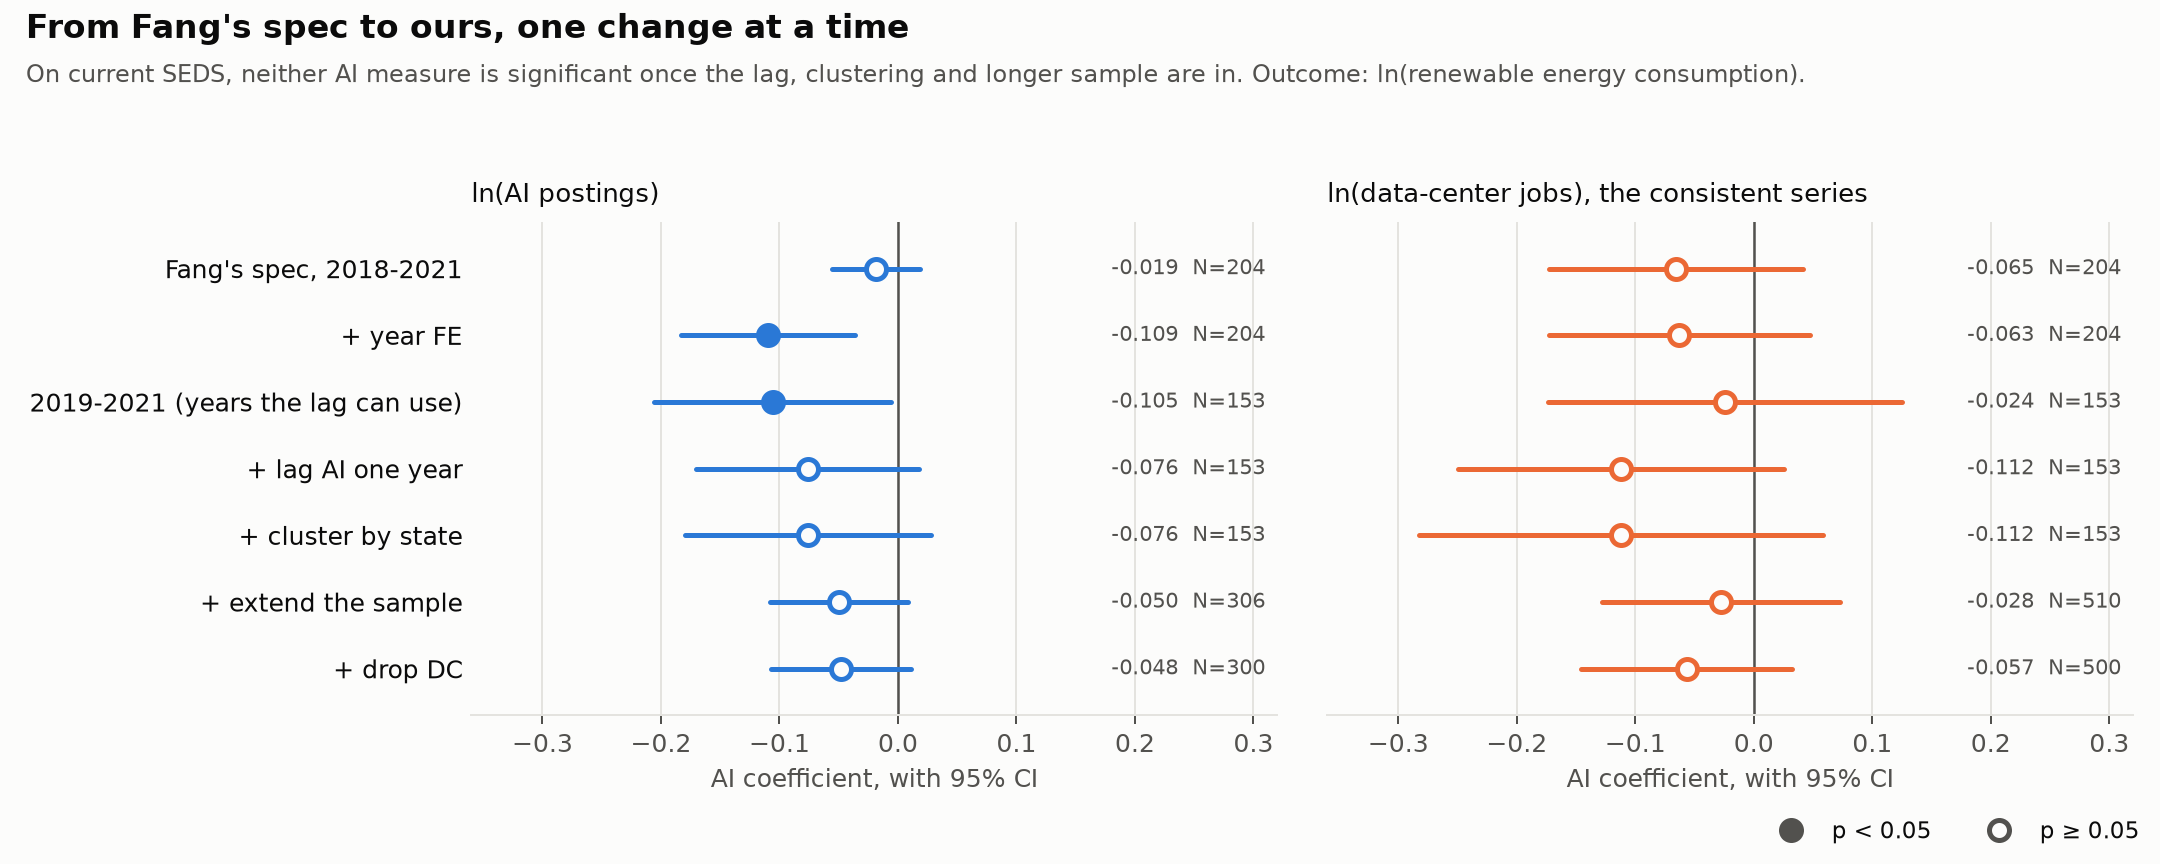

,Step,ln(AI postings),ln(share of national postings),ln(data-center jobs),"ln(jobs per 1,000)"
0,"Fang's spec, 2018-2021",-0.0188 (0.0187) [204],-0.0881*** (0.0334) [204],-0.0655 (0.0542) [204],-0.0743 (0.0528) [204]
1,+ year FE,-0.1095*** (0.0371) [204],-0.1094*** (0.0371) [204],-0.0628 (0.0558) [204],-0.0716 (0.0558) [204]
2,2019-2021 (years the lag can use),-0.1055** (0.0503) [153],-0.1054** (0.0503) [153],-0.0242 (0.0754) [153],-0.0360 (0.0754) [153]
3,+ lag AI one year,-0.0761 (0.0474) [153],-0.0761 (0.0474) [153],-0.1121 (0.0694) [153],-0.1215* (0.0696) [153]
4,+ cluster by state,-0.0761 (0.0518) [153],-0.0761 (0.0518) [153],-0.1121 (0.0850) [153],-0.1215 (0.0886) [153]
5,+ extend the sample,-0.0496* (0.0290) [306],-0.0492* (0.0290) [306],-0.0279 (0.0499) [510],-0.0301 (0.0509) [510]
6,+ drop DC,-0.0479 (0.0293) [300],-0.0475 (0.0293) [300],-0.0567 (0.0444) [500],-0.0596 (0.0453) [500]
7,"Check: 2019-2024, with DC",NaN,NaN,-0.0361 (0.0570) [306],-0.0427 (0.0583) [306]
8,"Check: 2019-2024, no DC",NaN,NaN,-0.0388 (0.0593) [300],-0.0463 (0.0606) [300]


In [10]:
display(Image('../results/2026-11-04/figures/04h_bridge.png', width=950))
display(pd.read_csv(T + 'bridge.csv'))

## 3. EPU moderation

In Fang's spec, AI x EPU is positive and significant for all three EPU measures. Fang finds only the state version significant (0.0160), so our state result is close and the other two differ. **Under two-way FE, none is significant,** and the AI slopes barely change between the 25th and 75th percentiles of EPU.

In [11]:
display(pd.read_csv(T + 'moderation.csv'))

,Spec,EPU,AI measure,AI x EPU,"AI slope, EPU p25","AI slope, EPU p75",N
0,Fang spec,Composite,AI postings,0.0215*** (0.0075),-0.0102 (0.0185),0.0082 (0.0205),204
1,Fang spec,Composite,Data-center jobs,0.0208*** (0.0073),-0.0761 (0.0531),-0.0583 (0.0530),204
2,Fang spec,National,AI postings,0.0211** (0.0081),-0.0150 (0.0180),0.0001 (0.0195),204
3,Fang spec,National,Data-center jobs,0.0201** (0.0080),-0.0800 (0.0531),-0.0656 (0.0528),204
4,Fang spec,State,AI postings,0.0193*** (0.0062),-0.0093 (0.0186),0.0150 (0.0215),204
5,Fang spec,State,Data-center jobs,0.0199*** (0.0061),-0.0798 (0.0521),-0.0549 (0.0523),204
6,Two-way FE,Composite,AI postings,0.0154 (0.0100),-0.0601* (0.0306),-0.0503* (0.0293),300
7,Two-way FE,Composite,Data-center jobs,0.0149 (0.0118),-0.0642 (0.0465),-0.0546 (0.0440),500
8,Two-way FE,National,AI postings,0.0159 (0.0104),-0.0589* (0.0307),-0.0488 (0.0293),300
9,Two-way FE,National,Data-center jobs,0.0153 (0.0126),-0.0652 (0.0466),-0.0557 (0.0441),500


## 4. By renewable type

In Fang's spec with postings, solar (positive) and biomass (negative) keep Fang's sign and significance. Wind is weaker (p = 0.078), and hydro loses significance. Under two-way FE, only biomass with postings stays significant (-0.0785, p = 0.016). No type is significant with data-center jobs.

In [12]:
display(pd.read_csv(T + 'by_type.csv'))

,Type,Fang Table 7,"Fang spec, postings","Fang spec, jobs","Two-way FE, postings","Two-way FE, jobs"
0,Wind,0.1542*** [164],0.0836* (0.0469) [164],0.0624 (0.1518) [164],-0.0107 (0.0605) [250],-0.3406 (0.2295) [412]
1,Solar,0.4970*** [204],0.3829*** (0.0712) [204],0.2188 (0.2250) [204],0.1193 (0.1438) [300],-0.0964 (0.2584) [500]
2,Geothermal,0.0210 [204],0.0414 (0.0679) [204],0.2035 (0.1964) [204],0.1974 (0.1828) [300],0.0638 (0.0625) [500]
3,Biomass,-0.0535*** [204],-0.1135*** (0.0260) [204],-0.0796 (0.0799) [204],-0.0785** (0.0313) [300],-0.0159 (0.0473) [500]
4,Hydro,0.1160*** [192],0.0212 (0.0421) [192],0.1433 (0.1224) [192],0.0142 (0.0625) [288],-0.0617 (0.0847) [480]


## 5. Heterogeneity

**Group definitions:** Fang says "the mean," but the group sizes look like median splits, so we show both. Fang's source for net producers isn't stated, and our definition gives 120 state-years against Fang's 76.

**Exploratory:** there are many tests here and no multiplicity correction, so a few p-values below 0.05 are expected by chance. Fang's pattern doesn't reproduce: for example, high-income states are +0.1236 in Fang and +0.0310 (p = 0.348) here.

In [13]:
display(pd.read_csv(T + 'heterogeneity.csv'))
display(pd.read_csv(T + 'regions.csv'))

,Split,AI measure,Fang high,Fang low,High group,Low group,Two-way FE: slope high,Two-way FE: slope low,Difference
0,Electricity use (mean),AI postings,-0.0025,0.0730**,-0.0388** (0.0189) [80],-0.0049 (0.0280) [124],-0.0427 (0.0280),-0.0472* (0.0281),0.0045 (0.0206)
1,Electricity use (mean),Data-center jobs,-0.0025,0.0730**,-0.1071 (0.0729) [80],-0.0545 (0.0710) [124],-0.0622 (0.0823),-0.0548 (0.0601),-0.0073 (0.1131)
2,Electricity use (median),AI postings,-0.0025,0.0730**,-0.0466** (0.0192) [100],-0.0010 (0.0306) [104],-0.0441 (0.0289),-0.0474* (0.0280),0.0033 (0.0216)
3,Electricity use (median),Data-center jobs,-0.0025,0.0730**,-0.0537 (0.0752) [100],-0.0648 (0.0762) [104],-0.0507 (0.0814),-0.0589 (0.0606),0.0082 (0.1128)
4,Electricity price (mean),AI postings,0.0628**,0.0334,-0.0736 (0.0454) [56],-0.0013 (0.0183) [148],-0.0866** (0.0371),-0.0267 (0.0270),-0.0599** (0.0284)
5,Electricity price (mean),Data-center jobs,0.0628**,0.0334,-0.1786 (0.1553) [56],-0.0847 (0.0512) [148],-0.1499* (0.0821),-0.0094 (0.0513),-0.1405 (0.1058)
6,Electricity price (median),AI postings,0.0628**,0.0334,-0.0346 (0.0310) [100],-0.0036 (0.0222) [104],-0.0614* (0.0359),-0.0375 (0.0284),-0.0238 (0.0240)
7,Electricity price (median),Data-center jobs,0.0628**,0.0334,0.0223 (0.1019) [100],-0.1338** (0.0583) [104],-0.0628 (0.0679),-0.0500 (0.0626),-0.0128 (0.0967)
8,R&D (mean),AI postings,0.0163,0.0704**,-0.0448 (0.0437) [48],-0.0160 (0.0215) [156],-0.0342 (0.0422),-0.0451 (0.0280),0.0109 (0.0326)
9,R&D (mean),Data-center jobs,0.0163,0.0704**,-0.0898 (0.1259) [48],-0.0516 (0.0618) [156],-0.0269 (0.1518),-0.0603 (0.0482),0.0335 (0.1642)


,Region,Fang Table 5,"Split, AI postings","Two-way FE, AI postings","Split, Data-center jobs","Two-way FE, Data-center jobs"
0,West,0.1176**,-0.0156 (0.0398) [52],-0.0193 (0.0360),-0.2636 (0.1741) [52],0.0991 (0.1724)
1,South,-0.0409,-0.0734*** (0.0234) [68],-0.0527** (0.0217),-0.0825 (0.0634) [68],-0.0543 (0.0480)
2,Northeast,0.0235,-0.0122 (0.0823) [36],-0.1092** (0.0423),-0.0246 (0.2133) [36],-0.2170** (0.0832)
3,Midwest,0.0626**,0.0571** (0.0266) [48],-0.0232 (0.0291),0.0322 (0.0775) [48],0.0693 (0.0672)


## 6. Placebo

AI(t+1) isn't significant for either measure, so this doesn't show reverse timing. That's weak evidence, though: AI(t-1) isn't significant either, and lead and lag correlate at 0.71-0.72.

In [14]:
display(pd.read_csv(T + 'placebo.csv'))

,AI measure,N,AI(t-1) alone,AI(t+1) alone,Both: lead,Both: lag,Within corr
0,AI postings,300,-0.0479 (0.0293),-0.0518 (0.0356),-0.0353 (0.0305),-0.0335 (0.0229),0.708
1,Data-center jobs,496,-0.0573 (0.0440),-0.0530 (0.0453),-0.0146 (0.0512),-0.0494 (0.0519),0.723


## 7. Robustness

Only postings with ctrl4 is significant (-0.0616, p = 0.034). The RPS control, using the LBNL current RPS/CES schedule, changes no result.

In [15]:
display(pd.read_csv(T + 'robustness.csv'))

,Check,AI postings,Data-center jobs
0,Final bridge spec,-0.0479 (0.0293) [300],-0.0567 (0.0444) [500]
1,Outcome: ln(renewable share of total energy),-0.0575* (0.0294) [300],-0.0623 (0.0438) [500]
2,Drop 2020,-0.0567* (0.0312) [250],-0.0593 (0.0438) [450]
3,Add LBNL current RPS/CES schedule,-0.0422 (0.0309) [300],-0.0562 (0.0439) [500]
4,ctrl4 controls,-0.0616** (0.0282) [300],-0.0326 (0.0545) [500]
